# ClimX Playground

This notebook provides a end-to-end pipeline for model development. 

In [1]:
#Autoreload .py files
%load_ext autoreload
%autoreload 2

Uset the `setup_logger` function to set the logging level to `INFO` or `DEBUG` at any time during the notebook.

In [2]:
from src.utils.logging_utils import setup_logger, logging
setup_logger(logging.INFO)

2026-11-04 15:33:19,144 - root - INFO - Logger configured with level: INFO


# Data loading and preprocessing

Data can be found at hugging face link 

In [13]:
# Import necessary libraries
import xarray as xr
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import numpy as np
import pandas as pd

# Date formatting
pd.options.future.infer_string = False


# Set plot style
plt.style.use('ggplot')
sns.set_context("notebook", font_scale=1.2)

# Configure plots to be larger
plt.rcParams['figure.figsize'] = [12, 8]

# Display all rows and columns of xarray datasets
xr.set_options(display_width=200, display_max_rows=200)

# Define data version
DATA_VERSION = 'lite' # Options: 'lite', 'full'
stationarization_mode = 'monthly'

# Define variables configuration
TARGET_VARIABLES = ['huss', 'pr', 'psl', 'sfcWind', 'tas', 'tasmax', 'tasmin']
GREENHOUSE_GAS_AGENTS = ['CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC']
AEROSOL_AGENTS = ['BC_AX', 'BC_N', 'SO2', 'SO4_PR', 'OM_NI']
ALL_FORCING_VARS = GREENHOUSE_GAS_AGENTS + AEROSOL_AGENTS

# Path to the data
# data_path = Path('/data/users/climate_challenge/upload_artifacts/')
# nc_data_path = data_path / 'ncfiles'
data_path = Path('./data/')

/tmp/ipykernel_625371/795825378.py:10: Pandas4Warning: The 'future.infer_string' option is deprecated and will be removed in pandas 4.0. Inferring str dtype for string data has been the default since pandas 3.0, and it will no longer be possible to disable it.
  pd.options.future.infer_string = False


In [4]:
# --- Ensure data exists locally; otherwise download from Hugging Face ---
import os
from pathlib import Path
from src.utils.hugging_face_utils import get_dataset_from_hf

# Download into data_path if not already present
get_dataset_from_hf(data_path, variant=DATA_VERSION)

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data already present: data
2026-11-04 15:33:31,211 - httpx2 - INFO - HTTP Request: GET https://huggingface.co/api/agent-harnesses "HTTP/1.1 200 OK"


/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/huggingface_hub/utils/_validators.py:189: UserWarning: The `resume_download` argument is deprecated and ignored in `snapshot_download`. Downloads always resume whenever possible.
  warnings.warn(
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `snapshot_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


2026-11-04 15:33:31,324 - httpx2 - INFO - HTTP Request: GET https://huggingface.co/api/datasets/isp-uv-es/ClimX/revision/main "HTTP/1.1 200 OK"


Fetching 7 files: 100%|██████████| 7/7 [00:00<00:00, 216.30it/s]

Download complete.


In [5]:
# --- Load the dataset --- 
# if RuntimeError: NetCDF: HDF error, just re-run this cell and it should work 
from src.utils.hugging_face_utils import open_climx_virtual_datasets
dataset = open_climx_virtual_datasets(data_path, DATA_VERSION)

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return fu

In [6]:
# --- Preprocess the data (id needed) ---
from src.data_preprocessing.preprocessing import preprocess_train

preprocessing_path = Path(f"preprocessing_data_{DATA_VERSION}/") 
precomputed = False
save_preprocessed = True

# Load and preprocess the training data
if not precomputed:
    X_train, y_train, metadata = preprocess_train(
        dataset, 
        preprocessing_path=preprocessing_path,
        version=DATA_VERSION,
        scaling_params_path=None, #'preprocessing_data_lite/scaling_psarams_lite.json'
    )
    if save_preprocessed:
        X_train = X_train.chunk({'time': 30, 'lat': -1, 'lon': -1})
        X_train.to_netcdf(f'preprocessing_data_{DATA_VERSION}/X_train.nc')
        y_train = y_train.chunk({'time': 30, 'lat': -1, 'lon': -1})
        y_train.to_netcdf(f'preprocessing_data_{DATA_VERSION}/y_train.nc')
else:
    X_train = xr.open_dataset(preprocessing_path / 'X_train.nc')
    y_train = xr.open_dataset(preprocessing_path / 'y_train.nc')

2026-11-04 15:33:38,273 - src.data_preprocessing.preprocessing - INFO - All forcing variables from config: ['BC_AX', 'BC_N', 'SO2', 'SO4_PR', 'OM_NI', 'CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC']
2026-11-04 15:33:38,274 - src.data_preprocessing.preprocessing - INFO - Available yearly forcings found in dataset: ['CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC']
2026-11-04 15:33:38,274 - src.data_preprocessing.preprocessing - INFO - Available monthly forcings found in dataset: ['BC_AX', 'BC_N', 'SO2', 'SO4_PR', 'OM_NI']
2026-11-04 15:33:38,274 - src.data_preprocessing.preprocessing - INFO - Available daily forcings found in dataset: []
2026-11-04 15:33:38,274 - src.data_preprocessing.preprocessing - INFO - Upsampling 'CO2_LBC' from 'time_year' dimension.
2026-11-04 15:33:38,768 - src.data_preprocessing.preprocessing - INFO - Upsampling 'N2O_LBC' from 'time_year' dimension.
2026-11-04 15:33:39,360 - src.data_preprocessing.preprocessing - INFO - Upsampling 'CH4

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return func(*(_execute_task(a, cache) for a in args))
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/dask/core.py:127: RuntimeWarning: invalid value encountered in divide
  return fu

# Training 

In [7]:
# Define model to train
model_type = 'nn' # implemented options in models/: climatology, nn, gnn 

# Instantiate the appropriate model
if model_type == 'climatology':
    from src.models.climatology_model import ClimatologyBaseline
    emulator = ClimatologyBaseline()
    model_path = Path(f'models_{DATA_VERSION}') / f'{model_type}.nc'
    trainer_params = {} # No training parameters needed for climatology model
    
elif model_type == 'nn':
    from src.models.nn_model import NNBaseline
    import torch
    torch.manual_seed(42)  # For reproducibility
    # NN model requires parameters at initialization
    model_params = {
        'n_lat': 192, # This should match the subsampled data
        'n_lon': 288, # This should match the subsampled data
        'n_forcing_vars': 22,
        'n_target_vars': 7,
        'learning_rate': 1e-3,
        'separate_output_heads': True, # Whether to have separate output heads for each variable
    }
    model_path = Path(f'models_{DATA_VERSION}') / f'{model_type}'
    trainer_params = {'max_epochs': 5, 'model_path': model_path,}
    # Add: time_chunk and pixel_batch 

    emulator = NNBaseline(model_params)

elif model_type == 'gnn':
    from src.models.gnn_model import GNNBaseline
    import torch
    torch.manual_seed(42)  # For reproducibility
    # NN model requires parameters at initialization
    folder = "src/models/adjacency/"
    graph_size = DATA_VERSION+"_" if DATA_VERSION == 'lite' else ''
    graph = 'random0.000001'  # Options: 'spatial', "spatial_0.000001", 'random0.000001', 'random0.00001'
    edge_index = torch.load(f"{folder}{graph_size}{graph}_edge_index.pt")
    model_params = {
        'edge_index': edge_index,
        'n_forcing_vars': 22,
        'n_target_vars': 7,
        'learning_rate': 1e-3,
        #'separate_output_heads': True, # Whether to have separate output heads for each variable
    }
    model_path = Path(f'models_{DATA_VERSION}') / f'{model_type}_{graph}'
    trainer_params = {'max_epochs': 5, 'model_path': model_path} 

    emulator = GNNBaseline(model_params)
else:
    raise ValueError(f"Unknown model type: {model_type}")

print(f"Using '{model_type}' model. Model will be saved to: {model_path}")

2026-11-04 15:36:27,673 - pint.util - WARNING - Redefining 'percent' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,673 - pint.util - WARNING - Redefining '%' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,674 - pint.util - WARNING - Redefining 'year' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,674 - pint.util - WARNING - Redefining 'yr' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,674 - pint.util - WARNING - Redefining 'C' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,674 - pint.util - WARNING - Redefining 'd' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,675 - pint.util - WARNING - Redefining 'h' (<class 'pint.delegates.txt_defparser.plain.UnitDefinition'>)
2026-11-04 15:36:27,675 - pint.util - WARNING - Redefining 'degrees_north' (<class 'pint.delegates.txt_defparser.pl

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/torch/__init__.py:1617: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


Using 'nn' model. Model will be saved to: models_lite/nn


In [8]:
print(f"X_train: {X_train.nbytes / 1024**3:.2f} GB")
print(f"y_train: {y_train.nbytes / 1024**3:.2f} GB")
print(f"X_train dimensions: {X_train.sizes}")
print(f"y_train dimensions: {y_train.sizes}")

X_train: 1.24 GB
y_train: 0.53 GB
X_train dimensions: Frozen({'forcing_scenario': 3, 'time': 31389, 'lat': 12, 'lon': 18})
y_train dimensions: Frozen({'forcing_scenario': 3, 'time': 31389, 'lat': 12, 'lon': 18})


In [9]:
print("Number of forcing variables:", len(X_train.data_vars))
print("Forcing variables:", list(X_train.data_vars))

print("Number of target variables:", len(y_train.data_vars))
print("Target variables:", list(y_train.data_vars))

Number of forcing variables: 22
Forcing variables: ['CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC', 'BC_AX_positive', 'BC_AX_negative', 'BC_AX_zeros_mask', 'BC_N_positive', 'BC_N_negative', 'BC_N_zeros_mask', 'SO2_positive', 'SO2_negative', 'SO2_zeros_mask', 'SO4_PR_positive', 'SO4_PR_negative', 'SO4_PR_zeros_mask', 'OM_NI_positive', 'OM_NI_negative', 'OM_NI_zeros_mask', 'sin_doy', 'cos_doy']
Number of target variables: 7
Target variables: ['huss', 'pr', 'psl', 'sfcWind', 'tas', 'tasmax', 'tasmin']


2026-11-04 15:36:36,346 - src.models.nn_model - INFO - {'max_epochs': 5, 'model_path': PosixPath('models_lite/nn')}
2026-11-04 15:36:36,379 - src.models.nn_model - INFO - NNBaseline fitting ...
2026-11-04 15:36:36,444 - pytorch_lightning.utilities.rank_zero - INFO - GPU available: True (cuda), used: True
2026-11-04 15:36:36,444 - pytorch_lightning.utilities.rank_zero - INFO - TPU available: False, using: 0 TPU cores


/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/lightning_fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /work/riteshbachhar_uri_edu/.conda/envs/clima_emu_ne ...


2026-11-04 15:36:36,755 - pytorch_lightning.accelerators.cuda - INFO - LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
2026-11-04 15:36:36,810 - pytorch_lightning.callbacks.model_summary - INFO - 
  | Name      | Type       | Params | Mode 
-------------------------------------------------
0 | embedding | Embedding  | 442 K  | train
1 | fc1       | Linear     | 4.0 K  | train
2 | fc2       | Linear     | 16.5 K | train
3 | heads     | ModuleList | 903    | train
4 | relu      | ReLU       | 0      | train
-------------------------------------------------
463 K     Trainable params
0         Non-trainable params
463 K     Total params
1.855     Total estimated model params size (MB)
12        Modules in train mode
0         Modules in eval mode


/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/callbacks/model_checkpoint.py:751: Checkpoint directory /work/pi_gkhanna_uri_edu/riteshbachhar_uri_edu/Research/MLProject/ClimX/models_lite/nn exists and is not empty.


Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:433: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/utilities/data.py:123: Your `IterableDataset` has `__len__` defined. In combination with multi-process data loading (when num_workers > 1), `__len__` could be inaccurate if each worker is not configured independently to avoid having duplicate data.


... (14 outputs left out)

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:433: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/utilities/data.py:123: Your `IterableDataset` has `__len__` defined. In combination with multi-process data loading (when num_workers > 1), `__len__` could be inaccurate if each worker is not configured independently to avoid having duplicate data.


Epoch 4: 100%|██████████| 2409/2409 [05:02<00:00,  7.96it/s, train_loss_step=0.738, val_loss=0.832, train_loss_epoch=0.823]

/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/trainer/connectors/data_connector.py:433: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/pytorch_lightning/utilities/data.py:123: Your `IterableDataset` has `__len__` defined. In combination with multi-process data loading (when num_workers > 1), `__len__` could be inaccurate if each worker is not configured independently to avoid having duplicate data.


Epoch 4: 100%|██████████| 2409/2409 [06:12<00:00,  6.47it/s, train_loss_step=0.738, val_loss=0.826, train_loss_epoch=0.821]2026-11-04 16:07:42,061 - pytorch_lightning.callbacks.early_stopping - INFO - Metric val_loss improved by 0.007 >= min_delta = 0.0001. New best score: 0.826
2026-11-04 16:07:42,089 - pytorch_lightning.utilities.rank_zero - INFO - `Trainer.fit` stopped: `max_epochs=5` reached.
Epoch 4: 100%|██████████| 2409/2409 [06:12<00:00,  6.47it/s, train_loss_step=0.738, val_loss=0.826, train_loss_epoch=0.821]
2026-11-04 16:07:42,094 - src.models.nn_model - INFO - NNBaseline.fit completed.
2026-11-04 16:07:42,094 - src.models.nn_model - INFO - Final training loss: 0.8213
2026-11-04 16:07:42,104 - src.models.nn_model - INFO - NNBaseline model saved to models_lite/nn
'nn' model trained and saved to models_lite/nn


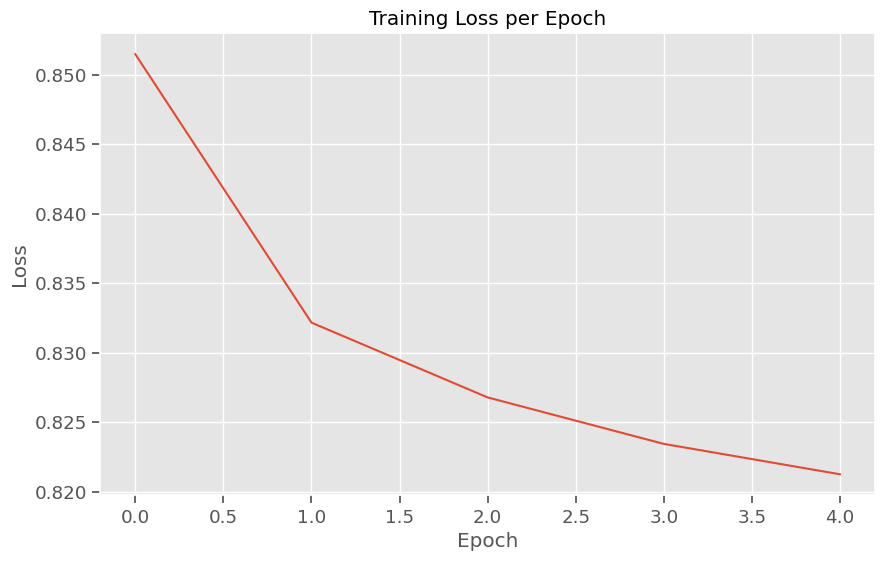

In [10]:
# Fit the model
FIT_MODEL = True

# Fit and save the model
if FIT_MODEL:
    emulator.fit(X_train, y_train, trainer_params=trainer_params)
    emulator.save(model_path)
    print(f"'{model_type}' model trained and saved to {model_path}")
else:
    # Load the model
    emulator.load(model_path / 'last.ckpt')
    print(f"'{model_type}' model loaded from {model_path}")

# Plot the loss
if hasattr(emulator, 'plot_loss'):
    emulator.plot_loss()

# Evaluation

In [14]:
# --- Evaluate the selected model ---
from src.data_preprocessing.preprocessing import preprocess_test

precomputed = False
save_preprocessed = True

# Load and preprocess the test data
if not precomputed:
    X_test, metadata_test = preprocess_test(
        dataset, 
        preprocessing_path=preprocessing_path,
        version='lite',
        scaling_params_path=preprocessing_path / f'scaling_parameters_{DATA_VERSION}.json',
    )
    if save_preprocessed:
        X_test = X_test.astype(np.float32).chunk({'time': 30, 'lat': -1, 'lon': -1})
        print("Saving X_test...")
        encoding = {var: {'zlib': False, '_FillValue': None} for var in X_test.data_vars}

        from dask.diagnostics import ProgressBar

        X_test.to_netcdf(preprocessing_path / "X_test.nc", encoding=encoding, compute=False)
       
else:
    import json 

    print("Loading preprocessed test data ...")
    X_test = xr.open_dataset(preprocessing_path / 'X_test.nc')
    metadata_test = {
        'climatology_path': str(preprocessing_path / f'climatology_{DATA_VERSION}.nc'),
        'scaling_params_path': str(preprocessing_path / f'scaling_parameters_{DATA_VERSION}.json'),
        'scaling_params': json.load(open(preprocessing_path / f'scaling_parameters_{DATA_VERSION}.json')),
        'stationarization_mode': stationarization_mode,
    }


# Define paths for evaluation results
results_path = Path(f'./results_{DATA_VERSION}/{model_type}_evaluation.json')
predictions_path = Path(f'./results_{DATA_VERSION}/{model_type}_predictions.zarr')

# Evaluate the model
y_pred, indices_pred = emulator.evaluate(
    X_test, 
    metadata_test, 
    results_path, 
    predictions_path,
    dataset.hist, 
    TARGET_VARIABLES=TARGET_VARIABLES,
    LOAD_PREDICTIONS=False,
    compute_indices=True,
 )

print(f"Evaluation for '{model_type}' model complete.")

2026-11-04 16:23:36,854 - src.data_preprocessing.preprocessing - INFO - All forcing variables from config: ['BC_AX', 'BC_N', 'SO2', 'SO4_PR', 'OM_NI', 'CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC']
2026-11-04 16:23:36,854 - src.data_preprocessing.preprocessing - INFO - Available yearly forcings found in dataset: ['CO2_LBC', 'N2O_LBC', 'CH4_LBC', 'CFC11eq_LBC', 'CF2CL2_LBC']
2026-11-04 16:23:36,855 - src.data_preprocessing.preprocessing - INFO - Available monthly forcings found in dataset: ['BC_AX', 'BC_N', 'SO2', 'SO4_PR', 'OM_NI']
2026-11-04 16:23:36,855 - src.data_preprocessing.preprocessing - INFO - Available daily forcings found in dataset: []
2026-11-04 16:23:36,855 - src.data_preprocessing.preprocessing - INFO - Upsampling 'CO2_LBC' from 'time_year' dimension.
2026-11-04 16:23:37,119 - src.data_preprocessing.preprocessing - INFO - Upsampling 'N2O_LBC' from 'time_year' dimension.
2026-11-04 16:23:37,976 - src.data_preprocessing.preprocessing - INFO - Upsampling 'CH4

Predicting: 100%|██████████| 1047/1047 [10:51<00:00,  1.61chunk/s]


2026-11-04 16:34:36,689 - src.models.emulator - INFO - Reversing preprocessing for predictions...
2026-11-04 16:34:36,697 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled huss using standardize method
2026-11-04 16:34:36,702 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled pr using standardize method
2026-11-04 16:34:36,708 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled psl using standardize method
2026-11-04 16:34:36,714 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled sfcWind using standardize method
2026-11-04 16:34:36,720 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled tas using standardize method
2026-11-04 16:34:36,726 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled tasmax using standardize method
2026-11-04 16:34:36,731 - src.data_preprocessing.preprocessing_utils - INFO - Unscaled tasmin using standardize method
2026-11-04 16:34:36,752 - src.data_preprocessing.preprocessing_utils - INFO - Va

Indices: R10mm: 100%|██████████| 15/15 [00:21<00:00,  1.45s/it] 

Evaluation for 'nn' model complete.


In [15]:
# --- Prepare Kaggle submission ---
import src.utils.kaggle_submission as ks
from src.utils.indices_utils import format_indices
precomputed_indices = False

if not precomputed_indices:
    # Format the indices and save as .nc (optional)
    indices_pred = format_indices(indices_pred, model_type, DATA_VERSION, save_indices=True)
    indices_pred = xr.Dataset(indices_pred)

    if DATA_VERSION == 'lite':
        # Upscale indices to original resolution (x16 in each spatial dimension).
        # IMPORTANT: your target grid (LAT/LON) extends beyond the coarse grid bounds,
        # and xarray fills out-of-bounds with NaN by default even with method='nearest'.
        # Using fill_value='extrapolate' prevents those edge NaNs by repeating boundary values.
        from src.utils.original_data_values import LAT, LON
        lat = np.asarray(LAT, dtype=float)
        lon = np.asarray(LON, dtype=float)

        # Make sure source coords are sorted/monotonic for interpolation
        indices_pred = indices_pred.sortby('lat').sortby('lon')
        indices_pred = indices_pred.interp(
            lat=lat,
            lon=lon,
            method='nearest',
            kwargs={'fill_value': 'extrapolate'},
        )

else:
    # Load the indices 
    indices_pred = xr.open_dataset(f"results_{DATA_VERSION}/{model_type}_indices.nc")

# Save the indices in the required format for Kaggle submission
submission_path = Path(f'submission_{DATA_VERSION}/submission_{model_type}.parquet')
ks.write_kaggle_submission_parquet(indices_pred, submission_path)

HDF5-DIAG: Error detected in HDF5 (1.14.6) thread 1:
  #000: H5F.c line 496 in H5Fis_accessible(): unable to determine if file is accessible as HDF5
    major: File accessibility
    minor: Not an HDF5 file
  #001: H5VLcallback.c line 3913 in H5VL_file_specific(): file specific failed
    major: Virtual Object Layer
    minor: Can't operate on object
  #002: H5VLcallback.c line 3848 in H5VL__file_specific(): file specific failed
    major: Virtual Object Layer
    minor: Can't operate on object
  #003: H5VLnative_file.c line 344 in H5VL__native_file_specific(): error in HDF5 file check
    major: File accessibility
    minor: Can't get value
  #004: H5Fint.c line 1055 in H5F__is_hdf5(): unable to open file
    major: File accessibility
    minor: Unable to initialize object
  #005: H5FD.c line 787 in H5FD_open(): can't open file
    major: Virtual File Layer
    minor: Unable to open file
  #006: H5FDsec2.c line 323 in H5FD__sec2_open(): unable to open file: name = '/work/pi_gkhanna_ur

PosixPath('submission_lite/submission_nn.parquet')

# Visualization of results

In [16]:
# Visualize the results
save_dir = Path(f"results_{DATA_VERSION}/{model_type}_visuals")
emulator.visualize(
    y_pred,
    indices_pred, 
    save_dir,
    variables_to_plot={'y': ['tas', 'tasmax', 'tasmin', 'pr', 'huss', 'psl', 'sfcWind'], 
                       'indices': ['FD', 'SU', 'ID', 'TR', 'GSL', 'CDD', 'CWD', 'SDII', 'R10mm', 'R95p', 'Rx5day', 'TXx', 'TNn', 'WSDI', 'CSDI']},
    time_index=50,
    lat=40.0,
    lon=-95.0
)
print(f"Visualizations saved to {save_dir}")

2026-11-04 16:41:07,066 - src.models.emulator - INFO - Visualizing results...


/work/riteshbachhar_uri_edu/.conda/envs/clima_emu_new/lib/python3.11/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


2026-11-04 16:41:08,179 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_map_tas_2015-02-20.png
2026-11-04 16:41:08,404 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_timeseries_tas_40.0_-95.0.png
2026-11-04 16:41:08,756 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_map_tasmax_2015-02-20.png
2026-11-04 16:41:08,971 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_timeseries_tasmax_40.0_-95.0.png
2026-11-04 16:41:09,321 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_map_tasmin_2015-02-20.png
2026-11-04 16:41:09,541 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_timeseries_tasmin_40.0_-95.0.png
2026-11-04 16:41:09,884 - src.visualization.utils - INFO - Saved plot to results_lite/nn_visuals/result_map_pr_2015-02-20.png
2026-11-04 16:41:10,124 - src.visualization.utils - INFO - Saved plot to result